# Sprint 3 - Statistics and New Features
I will check my Sprint 2 findings with simple statistical tests and make new useful columns.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')

df = pd.read_csv('Laptop_price_cleaned_final.csv')
print(df.shape)


(994, 7)


## Step 1 - Simple statistics

In [2]:
cols = ['Processor_Speed','RAM_Size','Storage_Capacity','Screen_Size','Weight','Price']
for c in cols:
    print(c, 'mean=', round(df[c].mean(),2), 'median=', round(df[c].median(),2), 'std=', round(df[c].std(),2))
print(df[cols].skew().round(3))
print(df[cols].kurt().round(3))


Processor_Speed mean= 2.76 median= 2.78 std= 0.72
RAM_Size mean= 15.43 median= 16.0 std= 10.84
Storage_Capacity mean= 583.66 median= 512.0 std= 310.52
Screen_Size mean= 14.06 median= 14.1 std= 1.68
Weight mean= 3.47 median= 3.47 std= 0.86
Price mean= 19490.47 median= 17272.01 std= 9308.61
Processor_Speed    -0.029
RAM_Size            0.589
Storage_Capacity    0.382
Screen_Size        -0.069
Weight              0.022
Price               0.397
dtype: float64
Processor_Speed    -1.174
RAM_Size           -1.201
Storage_Capacity   -1.498
Screen_Size        -1.111
Weight             -1.168
Price              -1.470
dtype: float64


Price mean is 19490 and std is 9309, so variation is high. Skew of Price is 0.40, so right side tail is longer. Kurt is negative, so distribution is flat, not sharp peak. Correlation of Storage with Price is 0.97, others are near zero. So only storage is strongly linked.

## Step 2 - Price distribution

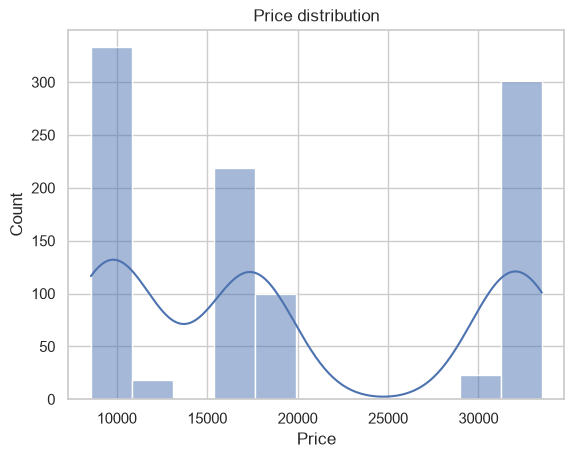

In [3]:
sns.histplot(df['Price'], kde=True)
plt.title('Price distribution')
plt.savefig('visuals/s3_price_dist.png', dpi=120)
plt.show()


In [4]:
print(stats.shapiro(df['Price'].sample(500, random_state=0)))
print('skew =', round(float(df['Price'].skew()), 3))


ShapiroResult(statistic=np.float64(0.8033564454604089), pvalue=np.float64(3.5018706715294824e-24))
skew = 0.397


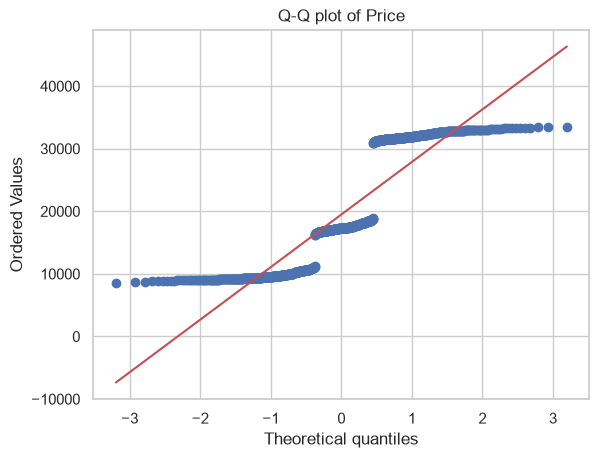

In [5]:
stats.probplot(df['Price'], plot=plt)
plt.title('Q-Q plot of Price')
plt.savefig('visuals/s3_qq.png', dpi=120)
plt.show()


Shapiro test p value is almost zero, so Price is not normal. It has two peaks and right skew. For shop this means: do not use one average price, use three price groups.

## Step 3 - Hypothesis testing (alpha = 0.05)

In [6]:
# Test 1: is 32GB RAM price really more than 4GB?
g4 = df[df['RAM_Size']==4]['Price']
g32 = df[df['RAM_Size']==32]['Price']
t = stats.ttest_ind(g4, g32, equal_var=False)
print(t)


TtestResult(statistic=np.float64(-2.6784722116804685), pvalue=np.float64(0.0076409779259739175), df=np.float64(496.7763154460813))


Null idea: both RAM groups have same average price. t = -2.68, p = 0.0076 which is less than 0.05, so I reject null. It means 32GB is really costlier. Shop can charge extra for RAM.

In [7]:
# Test 2: do brands have different average price?
labels = sorted(df['Brand'].unique())
groups = [df[df['Brand']==b]['Price'].values for b in labels]
print(stats.f_oneway(*groups))


F_onewayResult(statistic=np.float64(0.579086840027375), pvalue=np.float64(0.6778617668001445))


Null idea: all brands have same average price. F = 0.58, p = 0.678 which is more than 0.05, so I accept null. It means brand alone does not decide price. Shop should not put extra margin only for brand name.

In [8]:
# Test 3: brand and price group relation
q33 = df['Price'].quantile(0.33)
q66 = df['Price'].quantile(0.66)
df['Price_Cat'] = pd.cut(df['Price'], bins=[-1, float(q33), float(q66), float(df['Price'].max()+1)], labels=['Budget','Mid-Range','Premium'])
chi = stats.chi2_contingency(pd.crosstab(df['Brand'], df['Price_Cat']))
print('chi2 =', round(chi[0],2), 'p =', round(chi[1],4))


chi2 = 7.76 p = 0.4568


Null idea: brand and price group are independent. p = 0.457 which is more than 0.05, so I accept null. It means every brand sells in every price group. Shop should keep budget to premium models for each brand.

## Step 4 - Confidence interval (95 percent)

In [9]:
for c in ['Price','Processor_Speed','RAM_Size','Storage_Capacity']:
    m = df[c].mean()
    ci = stats.t.interval(0.95, len(df)-1, loc=m, scale=stats.sem(df[c]))
    print(c, 'mean =', round(m,2), 'CI =', (round(ci[0],2), round(ci[1],2)))


Price mean = 19490.47 CI = (np.float64(18911.08), np.float64(20069.86))
Processor_Speed mean = 2.76 CI = (np.float64(2.71), np.float64(2.8))
RAM_Size mean = 15.43 CI = (np.float64(14.75), np.float64(16.1))
Storage_Capacity mean = 583.66 CI = (np.float64(564.33), np.float64(602.99))


Price mean CI is 18911 to 20070. I am 95 percent sure true average price is in this range. Shop can use 19490 for sales planning and 17272 (median) for offer price.

## Step 5 - New features
I will make 5 new columns. Cut points are from data itself (quantiles and natural options), not random.

In [10]:
q33 = df['Price'].quantile(0.33)
q66 = df['Price'].quantile(0.66)
print('cuts:', round(float(q33),1), round(float(q66),1))

df['Price_Cat'] = pd.cut(df['Price'], bins=[-1, float(q33), float(q66), float(df['Price'].max()+1)], labels=['Budget','Mid-Range','Premium'])
df['RAM_Cat'] = pd.cut(df['RAM_Size'], bins=[-1, 8, 16, 100], labels=['Low (4-8GB)','Medium (16GB)','High (32GB)'])
df['Storage_Cat'] = df['Storage_Capacity'].map({256:'Small (256GB)', 512:'Medium (512GB)', 1000:'Large (1TB)'})
df['Weight_Cat'] = pd.cut(df['Weight'], bins=[0, 3.0, 4.0, 30], labels=['Light (<3kg)','Medium (3-4kg)','Heavy (>4kg)'])

# performance score = average of processor, ram, storage (scaled 0 to 1)
df['Perf_Score'] = (df['Processor_Speed']/df['Processor_Speed'].max() + df['RAM_Size']/32 + df['Storage_Capacity']/1000)/3
df['Performance_Cat'] = pd.qcut(df['Perf_Score'], 3, labels=['Low-Perf','Mid-Perf','High-Perf'])

print(df[['Price_Cat','RAM_Cat','Storage_Cat','Weight_Cat','Performance_Cat']].head())
df.to_csv('Laptop_price_featured_final.csv', index=False)
print(df.shape)


cuts:

 10741.6 18502.9


   Price_Cat        RAM_Cat     Storage_Cat      Weight_Cat Performance_Cat
0     Budget  Medium (16GB)   Small (256GB)    Light (<3kg)        Low-Perf
1     Budget    Low (4-8GB)   Small (256GB)    Light (<3kg)        Low-Perf
2  Mid-Range    Low (4-8GB)  Medium (512GB)    Light (<3kg)        Mid-Perf
3     Budget    High (32GB)   Small (256GB)    Light (<3kg)        Mid-Perf
4  Mid-Range    High (32GB)  Medium (512GB)  Medium (3-4kg)       High-Perf
(994, 13)


Why these columns: Price_Cat helps to plan budget/mid/premium stock. RAM_Cat and Storage_Cat match real shop options. Weight_Cat shows portable vs heavy. Performance_Cat mixes processor + RAM + storage to show overall power in one column.

## Step 6 - Check new features

In [11]:
print(df.groupby('Price_Cat', observed=True)['Price'].mean().round(1))
print(df.groupby('RAM_Cat', observed=True)['Price'].mean().round(1))
print(df.groupby('Storage_Cat', observed=True)['Price'].mean().round(1))
print(df.groupby('Weight_Cat', observed=True)['Price'].mean().round(1))
print(df.groupby('Performance_Cat', observed=True)['Price'].mean().round(1))


Price_Cat
Budget        9685.0
Mid-Range    16921.4
Premium      31498.9
Name: Price, dtype: float64
RAM_Cat
Low (4-8GB)      19102.6
Medium (16GB)    18899.1
High (32GB)      20764.2
Name: Price, dtype: float64
Storage_Cat
Large (1TB)       31601.3
Medium (512GB)    17493.0
Small (256GB)      9879.1
Name: Price, dtype: float64
Weight_Cat
Light (<3kg)      19237.0
Medium (3-4kg)    19473.7
Heavy (>4kg)      19797.7
Name: Price, dtype: float64
Performance_Cat
Low-Perf     11991.1
Mid-Perf     20848.7
High-Perf    25654.3
Name: Price, dtype: float64


In [12]:
print(pd.crosstab(df['Performance_Cat'], df['Price_Cat']))


Price_Cat        Budget  Mid-Range  Premium
Performance_Cat                            
Low-Perf            217        115        0
Mid-Perf             83        122      126
High-Perf            28         91      212


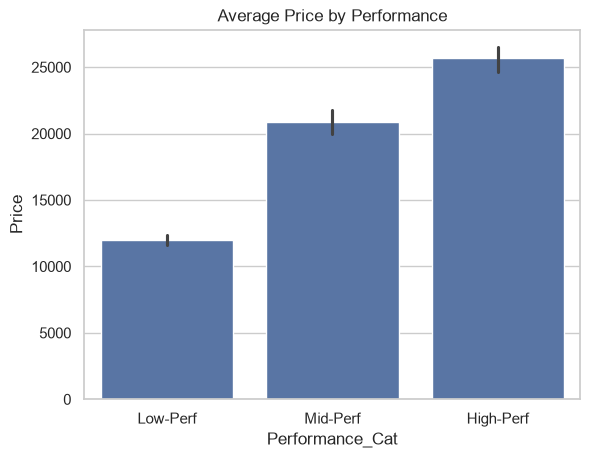

In [13]:
sns.barplot(data=df, x='Performance_Cat', y='Price', order=['Low-Perf','Mid-Perf','High-Perf'])
plt.title('Average Price by Performance')
plt.savefig('visuals/s3_perf_price.png', dpi=120)
plt.show()


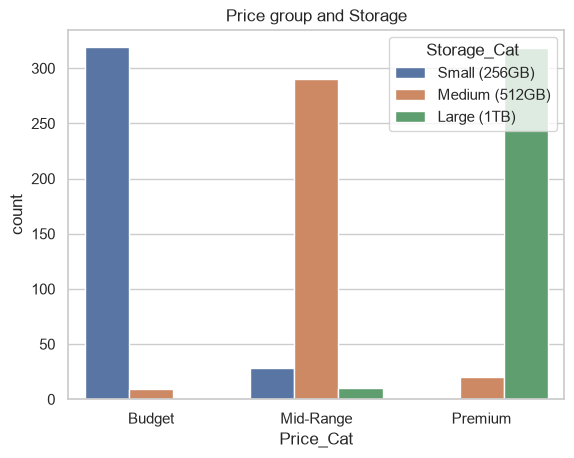

In [14]:
sns.countplot(data=df, x='Price_Cat', hue='Storage_Cat', order=['Budget','Mid-Range','Premium'])
plt.title('Price group and Storage')
plt.savefig('visuals/s3_price_storage.png', dpi=120)
plt.show()


What I found: Price groups are clear: Budget 9685, Mid 16921, Premium 31499. Storage groups are clear: 9879, 17493, 31601. Performance groups are clear: Low 11991, Mid 20849, High 25654. But Weight groups are almost same: 19237, 19474, 19798, so Weight is not useful for price. Low-Perf has zero Premium laptops, High-Perf has mostly Premium. So Price_Cat, Storage_Cat and Performance_Cat are useful.

## Step 7 - Final summary
- Most important feature: Storage, then Performance mix, then RAM. Processor, Screen, Weight and Brand alone are not important.
- Brands: all 5 brands have similar share and similar price.
- Price has budget, mid and premium groups.
- Best combo 32GB + 1TB costs 32885, lowest combo 4GB + 256GB costs 9274.
- Useful new columns: Price_Cat and Performance_Cat.

## My final suggestions for shop
1. Set price by storage: 256GB near 9879, 512GB near 17493, 1TB near 31601.
2. Budget models: 4-8GB + 256GB.
3. Premium models: 32GB + 1TB, mainly Lenovo.
4. Main stock: 16GB + 512GB mid-range.
5. Dell for value, Lenovo for premium, but keep all three price groups for each brand.
6. Do not decide price by weight or screen size.
7. Keep stock in ratio 33/33/34 for budget/mid/premium.